# Number Theory II
______

**References:**
* [[GCAC](https://toc.cryptobook.us/)] A Graduate Course in Applied Cryptography, Dan Boneh and Victor Shoup
* [[CINTA](https://shoup.net/ntb/)] A Computational Introduction to Number Theory and Algebra, Victor Shoup
* [[HAC](https://cacr.uwaterloo.ca/hac/)] Handbook of Applied Cryptography, Alfred J. Menezes, Paul C. van Oorschot and Scott A. Vanstone
* [[ITMC](https://www.cs.umd.edu/~jkatz/imc.html)] Introduction to Modern Cryptography, Jonathan Katz and Yehuda Lindell (2nd Edition)
* [Elementary number theory in sage](http://doc.sagemath.org/html/en/constructions/number_theory.html)

**Dependencies:**

This notebook uses [sage math](https://www.sagemath.org/) as kernel

In [1]:
import sage.misc.banner # sage math version info 
rchars = "┘─│┐┌└"
smallbanner = sage.misc.banner.banner_text(full=True)
for c in rchars:
    smallbanner = smallbanner.replace(c,"") # remove ascii art box
print(smallbanner)
#banner() # full banner with box


 SageMath version 9.5, Release Date: 2022-01-30                     
 Using Python 3.10.12. Type "help()" for help.                      



### Primes in sage
See also [sage documentation on primes](http://doc.sagemath.org/html/en/reference/sets/sage/sets/primes.html)

In [64]:
P = Primes(); P # define set of all primes in sage

Set of all prime numbers: 2, 3, 5, 7, ...

____

#### Fermat primality test 

The Fermat primality test is the simplest probabilistic primality test, which actually tests if the given number $ n $ is composite or *may be* prime. 

> Given an integer $ n $, choose some integer $ a $ coprime to $ n $ and calculate $ a^{n − 1} \pmod n$. If the result is different from $ 1 $, then $ n $ is composite. If it is $ 1 $, then $ n $ may be prime.
<p style="text-align:right;font-size:10px">
<a href="https://en.wikipedia.org/wiki/Primality_test">(source)</a>
<a href="https://en.wikipedia.org/wiki/Fermat_primality_test">(more info)</a>
<a href="https://en.wikipedia.org/wiki/Pseudoprime">(more info)</a>
</p>

If $ a^{n − 1} \pmod n = 1$ but $ n $ is *not* prime, then $ n $ is called a **pseudoprime to base $ a $**. 
An example would be $ n = 341 $ and $ a=2 $. There are only $ 21853 $ pseudoprimes to base $ 2 $ which are smaller than $ 2.5 \cdot 10^{10} $. 


In [87]:
gcd(341,2)

1

In [88]:
2^(341-1) % 341

1

In [89]:
341 in P 

False

#### Fermat's little theorem

The *Fermat primality test* follows from *Fermat's little theorem* which states that:

i) if $ n $ is a prime number, then for any integer $ a $, the number $a^{n} − a$ is an integer multiple of $ n $: 

$a^n \equiv a \pmod n $.

For example, if $ a = 2 $ and $ n = 7 $, then $ 2^7 = 128$ , and $ 128 − 2 = 126 = 7 \cdot 18$  is an integer multiple of $ 7 $.

ii) If $ a $ is not divisible by $ n $, that is, if $ a $ is coprime to $ n $, then Fermat's little theorem is equivalent to the statement that $ a^{n − 1} − 1$ is an integer multiple of $ n $:

$ a^{n − 1} \equiv 1 \pmod n $

For example, if $ a = 2 $ and $ n = 7 $, then $ 2^6 = 64 $, and $ 64 − 1 = 63 = 7 \cdot 9 $ is a multiple of $ 7 $. 

<p style="text-align:right;font-size:10px">
<a href="https://en.wikipedia.org/wiki/Fermat%27s_little_theorem">(more info)</a>
</p>

In [90]:
2**7 % 7 == 2 % 7

True

In [91]:
2**(7 - 1) % 7 == 1 % 7

True

#### Carmichael numbers

The composite numbers which have the property that $ a^{n-1} \equiv 1 \pmod n $ for every $ a $ that is coprime to $ n $ are called Carmichael numbers. The smallest Carmichael number is $ n = 561 $. 
<p style="text-align:right;font-size:10px">
<a href="https://en.wikipedia.org/wiki/Carmichael_number">(more info)</a>
</p>

______

In [56]:
# compute the modular multiplicative inverse python <= 3.7
def xgcd_python(a, b):
    if a == 0:
        return (b, 0, 1)
    else:
        g, y, x = xgcd_python(b % a, a)
        return (g, x - (b // a) * y, y) # ( gcd, x, y )

def inverse_mod_python(a, m):
    g, x, y = xgcd_python(a, m)
    if g != 1:
        raise Exception('modular inverse does not exist')
    else:
        return x % m

In [57]:
assert inverse_mod_python(2,15) == inverse_mod(2,15)

In [58]:
def ext_euclide(a,b,verbose=True): 
    """ verbose implementation of the extended Euclidean algorithm """
    # initialize values for computing gcd(a,b):
    r_last, r_now = a, b
    r_next = None
    # initialize values for computing coefficients 
    x_last, x_now = 1,0  
    y_last, y_now = 0,1  
    q, idx = None, 0
    if verbose: 
        print(f"{idx:3}:  r = {r_last:6}  q = {q or 'None':4}  x = {x_last:6}  y = {y_last:6} ")
    
    while r_next != 0:
        idx += 1     
        if r_next is not None:
            # omit in the first round 
            r_now, x_now, y_now = r_next, x_next, y_next
        assert r_now == x_now * a + y_now * b 
        
        q = r_last // r_now # quotient of this round
        if verbose: 
            print(f"{idx:3}:  r = {r_now:6}  q = {q or 'None':4}  x = {x_now:6}  y = {y_now:6} ")
        
        r_next = r_last - q * r_now   
        r_last = r_now
        
        x_next = x_last - q * x_now   
        x_last = x_now
        
        y_next = y_last - q * y_now   
        y_last = y_now  

    if verbose: 
        print(f"{idx+1:3}:  r = {r_next:6}  q = {q or 'None':4}  x = {x_next:6}  y = {y_next:6} ")
    return (r_now,x_now,y_now)

In [59]:
r = ext_euclide(240,46); assert r == xgcd(240,46); r

  0:  r =    240  q = None  x =      1  y =      0 
  1:  r =     46  q =    5  x =      0  y =      1 
  2:  r =     10  q =    4  x =      1  y =     -5 
  3:  r =      6  q =    1  x =     -4  y =     21 
  4:  r =      4  q =    1  x =      5  y =    -26 
  5:  r =      2  q =    2  x =     -9  y =     47 
  6:  r =      0  q =    2  x =     23  y =   -120 


(2, -9, 47)

In [60]:
def inverse_mod_ext_euclide(element,n):
    """ calculate modular multiplicative inverse using verbose impl. of ext_euclide """
    gcd,x,y = ext_euclide(element,n,verbose=False)
    assert gcd == 1,"given values are not coprime"
    return mod(x,n)

In [62]:
assert inverse_mod_ext_euclide(2,15) == inverse_mod(2,15)

In [105]:
eulers_phi_function(20)

8

**Example:** If $p=7$ then $ \mathbb{Z}^*_p = \{ 1,2,3,4,5,6 \} $ and $ \varphi(7) = 6 $

In [106]:
euler_phi(7)

6

#### Visualization of Euler's totient function when $n \in \textrm{Primes}$

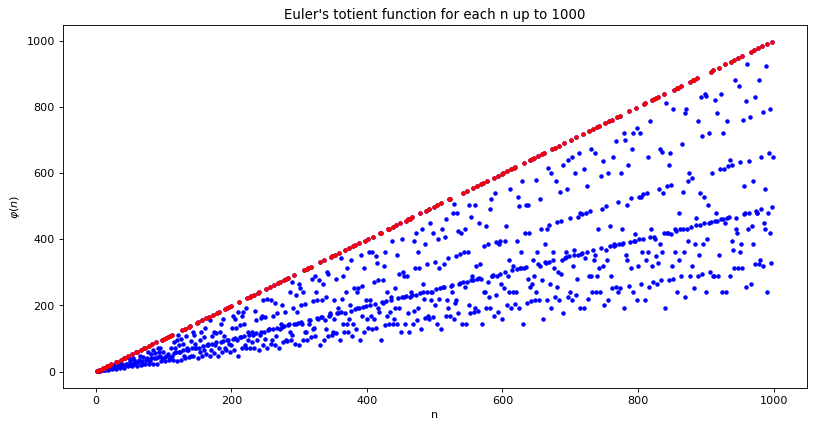

In [63]:
import matplotlib.pyplot as plt
n=1000
primes_up_to_n = list()
euler_phi_result_for_prime = list()
for i in range(1,n+1):
    if euler_phi(i) == i-1:
        primes_up_to_n.append(i)
        euler_phi_result_for_prime.append(euler_phi(i))
plt.figure(figsize=(12, 6), dpi=80)
plt.title(f"Euler's totient function for each n up to {n}")
plt.xlabel('n')
plt.ylabel('$\\varphi(n)$')
plt.plot(list(range(1,n)), [int(euler_phi(i)) for i in range(1,n)], 'b.')
plt.plot(primes_up_to_n,euler_phi_result_for_prime, 'r.')
plt.savefig("./figures/phi_n.png")
#plt.show()

<p style="text-align:center">
<img src="./figures/phi_n.png" alt="phi of n when n prime" width="800">
</p>
<p style="text-align:center;font-size:10px">
Phi of n, when n is prime the dot is colored red
</p>

### Euler's theorem to compute multiplicative inverses

As an alternative to the extended Euclidean algorithm, Euler's theorem may be used to compute modular multiplicative inverses [[cf.](https://en.wikipedia.org/wiki/Modular_multiplicative_inverse)]. Here $\varphi(n)$ denotes the Euler's totient function. 

Euler's theorem states that, if $x$ is *coprime* to $ n $, i.e., $\gcd(x,n)=1$ then:
$$
x^{\varphi(n)} \equiv 1 \pmod n 
$$

We can rewrite this exponent as $ 1 + (\varphi(n) - 1) $. If we use this in the formular we get:
$$
\begin{align*}
x^{1 + (\varphi(n) - 1)} &\equiv 1 \pmod n \\
x\cdot x^{\varphi(n) - 1} &\equiv 1 \pmod n \\
x^{\varphi(n) - 1} &\equiv 1/x \pmod n
\end{align*}
$$

Therefore a *modular multiplicative inverse* of $ x $ can be computed directly by:
$$
x ^{\varphi(n)-1} \equiv x^{-1} \pmod n
$$
In the special case where $ n \in \textrm{Primes}$, $\varphi(n) = n-1 $ a modular multiplicative inverse is given by:
$$
x^{-1} \equiv x^{n-2} \pmod n
$$
The disadvantages of this method are:
* That the value $\varphi(n)$ must be known (which requires knowing the factors of $n$).
* The computational cost of exponentiation.
> One notable advantage of this technique is that there are no conditional branches which depend on the value of a, and thus the value of a, which may be an important secret in public-key cryptography, can be protected from side-channel attacks. For this reason, the standard implementation of Curve25519 uses this technique to compute an inverse.

<p style="text-align:right;font-size:10px">
<a href="https://en.wikipedia.org/wiki/Modular_multiplicative_inverse">(source)</a>
</p>


In [112]:
bits=32
proof=True # use provable primality testing
p = random_prime(2**bits-1, proof=proof, lbound=2**(bits-1))
q = random_prime(2**bits-1, proof=proof, lbound=2**(bits-1))
n=p*q
phi_n=(p-1)*(q-1)

In [113]:
Zn = Integers(n)

In [114]:
x = Zn.random_element(); x

2902340178391946541

In [115]:
_x = Zn(x^(phi_n-1)); _x

4696244591587495893

In [116]:
_x = pow(int(x), int(phi_n-1), int(n)); _x # plain python (modular exponentiation)

4696244591587495893

In [117]:
assert Zn(x * _x)  == 1

From Euler's theorem it also follows that, for all elements in a multiplicative group $\mathbb{Z}^*_n$, where all elements are coprime to $ n $ (and thus invertible), any element raised to $\varphi(n)$ will yield the multiplicative identity element, i.e., $1$
$$
\forall x \in \mathbb{Z}^*_n: x^{\varphi(n)} \equiv 1 \pmod{n}
$$

**Example:**
$$
4^{\varphi(15)} = 4^8 = 65536 = 4369 \cdot 15 + 1 \equiv 1 \pmod{15}
$$

_____

## Group 
<a id='group'></a>
<div style="background:azure">
    
**DEFINITION: Group** (according to [[ITMC](https://www.cs.umd.edu/~jkatz/imc.html)]):

A group is a set $ \mathbb{G} $ along with a binary operation $ \circ $ for the following conditions hold:   
* **Closure:** For all $g,h \in \mathbb{G}, g \circ h \in \mathbb{G} $
* **Existence of an identity**: There exists an identity $ e \in \mathbb{G} $ such that for all $ g \in \mathbb{G}, e \circ g = g = g \circ e $
* **Existence of inverse:** For all $ g \in \mathbb{G} $ there exists an element $ h \in \mathbb{G} $ such that $ g \circ h = e = h \circ g $. Such an $ h $ is called an inverse of $ g $. 
* **Associativity:** For all $ g_1,g_2,g_3 \in \mathbb{G}, (g_1 \circ g_2) \circ g_3 = g_1 \circ (g_2 \circ g_3)$

A group $ \mathbb{G} $ with operation $\circ$ is *abelian* if the following holds:
* **Commutativity:** For all $ g,h \in \mathbb{G}$, $g \circ h = h \circ g $

When $ \mathbb{G} $ has a finite number of elements, we say $ \mathbb{G} $ is *finite* and let $ | \mathbb{G} | $ denote the *order* of the group i.e., the number of elements in $ \mathbb{G} $. 

If $ \mathbb{G} $ is a group, a set $ \mathbb{H} \subseteq \mathbb{G}$ is a *subgroup* of $ \mathbb{G} $ if $ \mathbb{ H } $ itself forms a group under the same operation associated with $ \mathbb{G} $. Every group $ \mathbb{G} $ has the trivial subgroups $ \mathbb{G} $ and $ \{e\} $. 

</div>    

### Additive and multiplicative notation for the group operation $\circ$

**Additive notation**:    
* group operation with two elements $ g + h $
* identity: $ 0 $ 
* inverse of element $g$ is given by $ -g $
* we write $ h - g $ instead of $ h + (-g) $

**Multiplicative notation**:
* group operation with two elements $ g \cdot h $ or $ gh $
* identity: $ 1 $
* inverse of element $g$ is given by $ g^{-1} $ (or $ 1/g $)
* we sometimes write $ h/g $ instead of $ hg^{-1} $

### Properties of groups
* A group is called *cyclic*, if there is a generator $g \in G$, such that for each $x \in G$, there is an integer $i$ where $x=g^i$
* The *order* of a finite group is the number of its elements i.e., $|G|$
    + A group is called *finite*, if $|G|$ (its order) is finite.
* The *order* of an element $a$ of the group is the smallest positive integer $r$ such that, $a^r=e$ where $e$ is defined as identity element of the group. If no such $r$ exists the element $a$ has an infinite order.

### Examples for groups

* The set of integers $\mathbb{Z}$ with the operation of addition ($+$), where the identity element would be $e=0$ and the inverse of an element would be the negative integer.

* This set is an *abelian group* with infinite order.

In [118]:
# Closure example:
g=3; h=7 # some elements in Z 
g in Z and h in Z and g+h in Z

True

In [119]:
# Identity example:
g=3; e=0 # identity element 
e + g == g == g + e 

True

In [120]:
# Inverse example: 
g=3; _g=-3 # inverse of g
g + _g == e == _g + g

True

In [121]:
# Associativity example:
g1=3; g2=7; g3=23
(g1 + g2) + g3 == g1 + (g2 + g3)

True

In [122]:
# Commutativity example:
g=3; h=7
g + h == h + g

True

### Examples for groups

* The set of integers $\mathbb{Z}$ with the operation of multiplication ($*$) is *not* a *group* since not every element has an inverse in the integers. The identity element would be $e=1$, but $ 2 $ for example has no inverse in the integers, as $ 2 \cdot \frac{1}{2} = 1 $, but $\frac{1}{2} \notin \mathbb{Z}$. 

* The set of real numbers $\mathbb{R}$ under the operation of multiplication ($*$) is *not* a *group* since $0$ does not have an inverse. 

* The set of real numbers $\mathbb{R}$ without $zero$ under the operation of multiplication ($*$) is a *group* with the identity $1$. 

### Examples for groups

* The set of integers modulo $ n $, i.e., $ \mathbb{Z}_n $, where $ n > 1 $,  is an *abelian group* under the operation of addition ($+$) modulo $ n $, i.e., $ a + b := [ a + b \mod n ] $. This group can also be denoted as $\mathbb{Z}^+_n $. The order of this group is $ n $, with the elements $ \{ 0, ..., n - 1 \} $. The inverse of any element $ a $ is $ [(n-a) \mod n] $

In [123]:
n=15; Zn = Integers(n); Zn

Ring of integers modulo 15

In [124]:
# alternative way to define an additive group Z_n 
Zn_add = AdditiveAbelianGroup([n]); Zn_add

Additive abelian group isomorphic to Z/15

In [125]:
print(f"Z_n order = {Zn.order()}\nZ_n list  = {Zn.list()}")

Z_n order = 15
Z_n list  = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]


In [126]:
print(f"Zn_add order = {Zn_add.order()}\nZn_add list  = {Zn_add.list()}")

Zn_add order = 15
Zn_add list  = [(0), (1), (2), (3), (4), (5), (6), (7), (8), (9), (10), (11), (12), (13), (14)]


In [127]:
g = Zn.random_element(); h = Zn.random_element()
print(f"g = {g}; h = {h}")

g = 0; h = 6


In [128]:
# Closure example:
g = Zn.random_element(); h = Zn.random_element()
g in Zn and h in Zn and g+h in Zn

True

In [129]:
# Identity element 0 in Zn under addition:
g = Zn.random_element(); e=Zn(0) 
e + g == g == g + e 

True

In [130]:
# Inverse of g mod n under addition is always n-g = -g 
# as g + (n-g) mod n = 0 
g = Zn.random_element(); _g=Zn(n-g) # inverse of g mod n 
g + _g == e == _g + g

True

In [131]:
# Associativity example:
g1=Zn.random_element(); g2=Zn.random_element(); g3=Zn.random_element()
(g1 + g2) + g3 == g1 + (g2 + g3)

True

In [132]:
# Commutativity example:
g = Zn.random_element(); h = Zn.random_element()
g + h == h + g

True

In [133]:
# Generator of Zn under addition, therefore the group is also cyclic 
Zn_add.gens_dict()

{'(1)': (1)}

In [134]:
g=Zn(1) # generator
group=list()
for i in range(0,n):
    group.append(i*g) # i*g = g + g + ... + g (i times)
group

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 0, 1]

### Examples for groups

* $ \mathbb{Z}_n \setminus \{0\} = \{1,\dots,n-1\} $ is *not* a *group* with operation $ a \cdot b \mod n $ being multiplication modulo $ n $, where $ n \notin \textrm{Primes}$.
* The identity element would be $e=1$, but not every element has a modular multiplicative inverse, e.g., for $ n = 15 $ the element $ 3 $ has no inverse, since $ \gcd(3,15) = 3 \neq 1 $ (closure fails as well: $ 3 \cdot 5 = 0 \pmod{15} $).
* Removing all non-invertible elements yields $ \mathbb{Z}_n^* = \{ x \in \mathbb{Z}_n : \gcd(x,n)=1 \} $, which *is* an abelian group under multiplication modulo $ n $ for *every* $ n > 1 $, with order $ \varphi(n) $.

In [135]:
# Z_n has n elements
n=15; Zn = Zmod(n)
print(f"{Zn.list()} len = {Zn.order()}")

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] len = 15


In [136]:
# but not every element has a modulo multiplicative inverse mod n
Zn_unit = Zn.unit_group() # Zn_unit only has invertible elements (aka. units)
#print(type(Zn_unit))
print(f"{Zn_unit.list()} len = {Zn_unit.order()}") # show list of elements as represented by generators
print(f"(f0,f1) = {Zn_unit.gens_values()}") # show values of generators

(1, f1, f1^2, f1^3, f0, f0*f1, f0*f1^2, f0*f1^3) len = 8
(f0,f1) = (11, 7)


In [137]:
assert Zn_unit.order() < Zn.order() # there not all elements in Zn can be invertible

In [138]:
# compute the set of all invertible elements in Zn 
Zn_inv = [ x for x in Zn if Zn(x**euler_phi(n)) == Zn(1) ] 
print(len(Zn_inv)) # number of invertible elements Zn
Zn_inv 

8


[1, 2, 4, 7, 8, 11, 13, 14]

### Examples for groups

* The set $ \mathbb{Z}^*_p $ (without the element $0$) is a *group* under operation $ a \cdot b \mod p $ being multiplication modulo $ p $, where $ p \in \textrm{Primes}$. Because of the removal of zero, the order of the group is $p-1$. 

In [139]:
p=7; p in P

True

In [140]:
Zp=Integers(p) # generate the group of invertible elements of Zp.
# Since p is prime every element except 0 has an multiplicative inverse modulo p 
Zp_unit=Zp.unit_group() 
print(f"Zp: \norder = {Zp.order()} \tlist = {Zp.list()} \ntype = {type(Zp)}")
print(f"Zp_unit: \norder = {Zp_unit.order()} \tlist = {Zp_unit.list()} \ntype = {type(Zp_unit)}")

Zp: 
order = 7 	list = [0, 1, 2, 3, 4, 5, 6] 
type = <class 'sage.rings.finite_rings.integer_mod_ring.IntegerModRing_generic_with_category'>
Zp_unit: 
order = 6 	list = (1, f, f^2, f^3, f^4, f^5) 
type = <class 'sage.groups.abelian_gps.values.AbelianGroupWithValues_class_with_category'>


In [141]:
# print actual values not variable names 
for element in Zp_unit.list():
    print(f"{element.value()}",end=",")

1,3,2,6,4,5,

In [142]:
Zp_unit.variable_names() # output the generators of the group as variables

('f',)

In [143]:
Zp_unit.gens_values() # output the generators as values 

(3,)

In [144]:
Zp_unit.inject_variables() # get variables from this group in this notebook 

Defining f


In [145]:
f.value() # output the value of this variable

3

In [146]:
Zp_unit.exponent() # the smallest positive number z such that g^z=1 for all g ∈ G

6

## Finite Field
<a id='gf'></a>
<div style="background:azure">
    
**DEFINITION: Finite Field** (according to [[ITMC](https://www.cs.umd.edu/~jkatz/imc.html)]):

A **finite field** (or **Galois field**), is a finite set $\mathbb{F}$ along with two binary operations $\{+,\cdot\} $ for which the following hold:

* $\mathbb{F}$ is an *abelian group* with respect to the operation $+$ and the identity element, denoted as $ 0 $, for this group.
    + The *additive inverse* of $ a \in \mathbb{F}$, denoted by $ -a $, is the unique element satisfying $ a + (-a) = 0 $.
    + We can also write $b-a$ in place of $b+(-a)$.
* $\mathbb{F} \setminus \{0\}$ is an *abelian group* with respect to the operation $\cdot$ and the identity element, denoted as $ 1 $, for this group.
    + The *multiplicative inverse* of $ a \in \mathbb{F} \setminus \{0\}$, denoted by $a^{-1}$, is the unique element satisfying $a\cdot a^{-1} = 1 $. 
    + We can also write $b/a$ in place of $b\cdot a^{-1}$.
    + We can also write $ab$ in place of $a \cdot b$.
* **Distributivity:** For all $a,b,c \in \mathbb{F}$ we have $ a \cdot (b+c) = a\cdot b + a\cdot c$


</div> 

See also:
* https://en.wikipedia.org/wiki/Field_(mathematics) 
* https://en.wikipedia.org/wiki/Finite_field
* https://mathworld.wolfram.com/FiniteField.html

### Properties of finite fields 
* The number of elements of a finite field is called its *order*. 
* If $\mathbb{F}$ is a finite field, then the *order* of $\mathbb{F}$ is a prime power, i.e., $p^n$ where $p \in \textrm{Primes}$ and $ n \geq 1 $.
    + Therefore, the order of a finite field is either prime ($p^1$), or the power of a prime ($p^n$ for all $n > 1$). 
    + Conversely, for every prime power $ q=p^n $ there is a finite field of that order $ q $, which is unique (up to relabeling of the elements).
    + For $ q = p^n $ with $p \in \textrm{Primes}$, we let $\mathbb{F}_q$ or $\mathtt{GF}(q)$ denote the (unique) field of order $ q $. We call $ p $ the *characteristic* of $\mathbb{F}_q$.  

### Examples of finite fields

**Prime field**: 
* The set $\{0,\dots,p-1\}$, where $p \in \textrm{Primes}$, under addition and multiplication modulo $ p$ is called a *prime field* $\mathbb{F}_p$. It is the field of residue classes modulo $ p $ written as $ a \equiv b \pmod{p} $. A prime field is of order $ p $. Adding $ p $ copies of any element always results in $ 0 $. The *characteristic* of this field is $ p $.
    + The elements of $\mathbb{F}_p$ are integers
    + $\mathbb{F}_p$ can also be called the *ring of integers modulo $ p $*
    + $\mathbb{F}_p^*$ means all elements of the field without the $0$.
    + When $ p = 2 $ in $\mathbb{F}_p $, also noted as $ \texttt{GF}(2)$, addition and subtraction is XOR and multiplication is AND. Since the only invertible element is $ 1 $, division is the identity function.

In [66]:
p = 2; assert p in P,"p not prime"
Fp = Integers(p)
print(f"Fp_order = {Fp.order()} Fp_characteristic = {Fp.characteristic()} Fp_modulus = {Fp.modulus()} \nFp = {Fp.list()}")
Fp

Fp_order = 2 Fp_characteristic = 2 Fp_modulus = x + 1 
Fp = [0, 1]


Ring of integers modulo 2

### Examples of finite fields
* For $q=p^n$ where $n > 1$ the set $\{0, . . . , q − 1\}$ is not a field under addition and multiplication modulo $q$. For example, if we take $ q = 3^2 = 9$ then the element $3$ does not have a multiplicative inverse modulo $9$ in this set.

In [147]:
p=11; assert p in P,"p not prime"
Fp = Integers(p) # define field as integers mod p in sage
print(f"Fp_order = {Fp.order()} Fp_characteristic = {Fp.characteristic()} Fp_modulus = {Fp.modulus()} \nFp = {Fp.list()}")
Fp

Fp_order = 11 Fp_characteristic = 11 Fp_modulus = x + 10 
Fp = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


Ring of integers modulo 11

In [148]:
type(Fp)

<class 'sage.rings.finite_rings.integer_mod_ring.IntegerModRing_generic_with_category'>

In [149]:
e_in_Fp = Fp.random_element()
print(f" element = {e_in_Fp}  type_of_element = {type(e_in_Fp)}")

 element = 4  type_of_element = <class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>


In [150]:
assert e_in_Fp*p == Fp(0) # test if a*p == 0 as it should be for this field

In [151]:
Fp = GF(p) # define field as finite field in sage
# Fp = FiniteField(p) # alias of GF() 
print(f"Fp_order = {Fp.order()} Fp_characteristic = {Fp.characteristic()} Fp_modulus = {Fp.modulus()} \nFp = {Fp.list()}")
Fp

Fp_order = 11 Fp_characteristic = 11 Fp_modulus = x + 10 
Fp = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


Finite Field of size 11

In [152]:
type(Fp)

<class 'sage.rings.finite_rings.finite_field_prime_modn.FiniteField_prime_modn_with_category'>

In [153]:
e_in_Fp = Fp.random_element()
print(f" element = {e_in_Fp}  type_of_element = {type(e_in_Fp)}")

 element = 5  type_of_element = <class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>


In [154]:
assert e_in_Fp*p == Fp(0) # test if a*p == 0 as it should be for this field

In [155]:
for i,x in enumerate(Fp): 
    # print elements of Fp with their type
    print(f"{i:>2d}: {x} \t{type(x)}")

 0: 0 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 1: 1 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 2: 2 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 3: 3 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 4: 4 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 5: 5 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 6: 6 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 7: 7 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 8: 8 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
 9: 9 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>
10: 10 	<class 'sage.rings.finite_rings.integer_mod.IntegerMod_int'>


**Extension field:**

* $\texttt{GF}(p^n)$, where $ n \in \mathbb{N} $ and $ n > 1 $, is called an **extension field**, and is the field of equivalence classes of polynomials whose coefficients belong to $\texttt{GF}(p)$. The prime $ p $ is called the *characteristic* of the field, and the positive integer $ n $ is called the *dimension* of the field over its prime field.

* Elements of $\texttt{GF}(p^n) $ may be represented as polynomials of degree less than $ n $ over $ \texttt{GF}(p) $.
$$
    a_{n-1}x^{n-1}+ \dots + a_1x^1 + a_0
$$
e.g., for $\texttt{GF}(2^3)$ 
$$
    a_2x^2 + a_1x^1 + a_0
$$
```
(a2, a1, a0)
(0, 0, 0) = 0
(0, 0, 1) = 1
(0, 1, 0) = x
(1, 0, 0) = x²
(0, 1, 1) = x+1
(1, 1, 0) = x²+x
(1, 0, 1) = x²+1
(1, 1, 1) = x²+x+1
```

* Operations are then performed modulo $ \texttt{R} $  where $ \texttt{R} $ is an irreducible polynomial of degree n over $ \texttt{GF}(p) $
* When the prime is $ 2 $, it is conventional to express elements of $ \texttt{GF}(p^n) $ as binary numbers, with each term in a polynomial represented by one bit in the corresponding element's binary expression. Braces ( "{" and "}" ) or similar delimiters are commonly added to binary numbers, or to their hexadecimal equivalents, to indicate that the value is an element of a field.


In [156]:
p=2
assert p in P,"p not prime"
q=p**3 # p^n
assert q not in P
GF_q = GF(q,'x') 
GF_order = GF_q.order()
print(f"GF_q_order = {GF_q.order()} GF_q_characteristic = {GF_q.characteristic()} GF_q_modulus = {GF_q.modulus()} \nFp = {GF_q.list()}")
GF_q

GF_q_order = 8 GF_q_characteristic = 2 GF_q_modulus = x^3 + x + 1 
Fp = [0, x, x^2, x + 1, x^2 + x, x^2 + x + 1, x^2 + 1, 1]


Finite Field in x of size 2^3

In [157]:
GF_q.modulus?

Docstring:     
   Return the minimal polynomial of the generator of "self" over the
   prime finite field.

   The minimal polynomial of an element a in a field is the unique
   monic irreducible polynomial of smallest degree with coefficients
   in the base field that has a as a root. In finite field extensions,
   \GF{p^n}, the base field is \GF{p}.

   OUTPUT:

   * a monic polynomial over \GF{p} in the variable x.

   EXAMPLES:

      sage: F.<a> = GF(7^2); F
      Finite Field in a of size 7^2
      sage: F.polynomial_ring()
      Univariate Polynomial Ring in a over Finite Field of size 7
      sage: f = F.modulus(); f
      x^2 + 6*x + 3
      sage: f(a)
      0

   Although f is irreducible over the base field, we can double-check
   whether or not f factors in F as follows. The command "F['x'](f)"
   coerces f as a polynomial with coefficients in F. (Instead of a
   polynomial with coefficients over the base field.)

      sage: f.factor()
      x^2 + 6*x + 3
      sage: F['x

In [158]:
for i,e in enumerate(GF_q):  
    print(f"{i:>2d}: {e}")
print(type(i),type(e))

 0: 0
 1: x
 2: x^2
 3: x + 1
 4: x^2 + x
 5: x^2 + x + 1
 6: x^2 + 1
 7: 1
<class 'int'> <class 'sage.rings.finite_rings.element_givaro.FiniteField_givaroElement'>


In [159]:
GF_q.degree()

3

# EOF